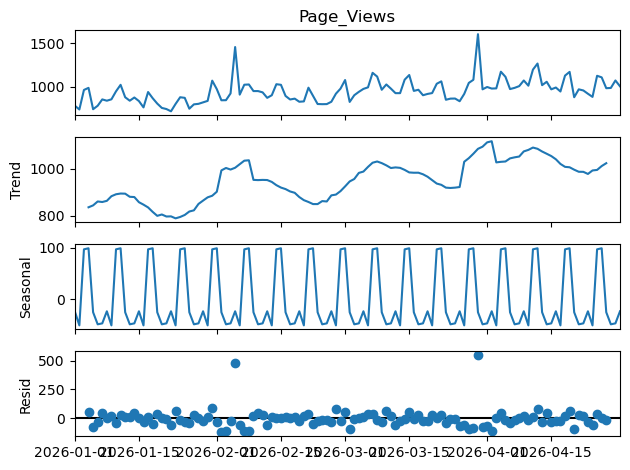

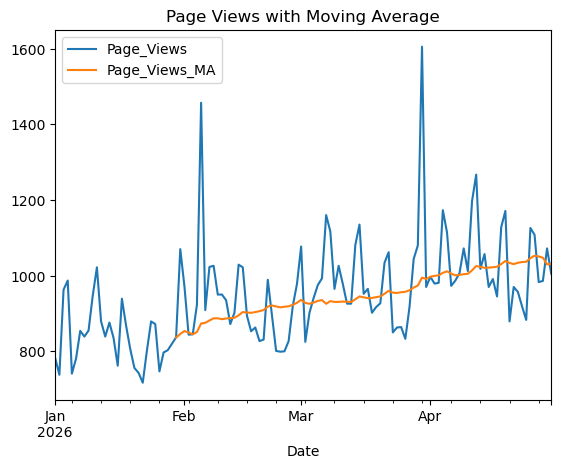

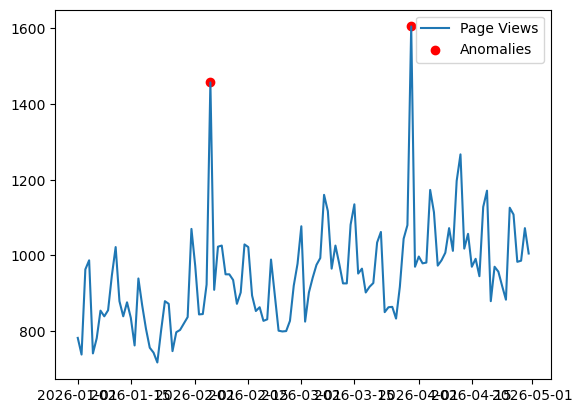

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose


data = pd.read_csv('exp6_website_traffic.csv', parse_dates=['Date'], index_col='Date')


decomposition = seasonal_decompose(data['Page_Views'], model='additive')
decomposition.plot()

plt.show()


data['Page_Views_MA'] = data['Page_Views'].rolling(window=30).mean()
data[['Page_Views', 'Page_Views_MA']].plot()
plt.title('Page Views with Moving Average')
plt.show()


data['Page_Views_Z'] = ((data['Page_Views'] - data['Page_Views'].mean()) /
data['Page_Views'].std())
anomalies = data[data['Page_Views_Z'].abs() > 3]
plt.plot(data.index, data['Page_Views'], label='Page Views')
plt.scatter(anomalies.index, anomalies['Page_Views'], color='red', label='Anomalies')
plt.legend()
plt.show()